# IIT Patna - CS3103: Machine Learning Project
## Project Title: Flood Area Segmentation with Teacher–Student Learning
**Course**: CS3103 Machine Learning  
**Roll Number**: 2401CS74  
**Author**: B.Tech Computer Science & Engineering, IIT Patna  
**Dataset**: Kaggle Flood Area Segmentation (290 samples)  
**Strict Classical ML Protocol**: Random Seed = 42, No Deep Learning, No External Data, Zero Data Leakage.

---

### Abstract
This project implements, evaluates, and analyzes classical machine learning pipelines for binary flood area segmentation using teacher–student knowledge distillation. Two parallel tracks are developed:
1. **Supervised Teacher–Student Learning (Track S)**: High-capacity teachers (KNN, Random Forest, Gaussian Naive Bayes) operating on 18-dimensional rich features ($\phi_T$) distill into budget-compliant compact students (6-dimensional features, $\phi_S$) via confident pseudo-labeling over $L \cup U$ (203 images) with threshold $\tau$-filtering and soft-label weighted duplication.
2. **Unsupervised Teacher–Student Learning (Track U)**: An 18-D K-Means teacher ($K_T=9$) discovered via inertia elbow analysis distills cluster centroid knowledge into compact 6-D students ($K_S=2$) across four architectural variants (with/without Lloyd refinement $\times$ inherited vs. re-estimated mapping).

Every model is evaluated on all 3,801,088 pixels across the 58 test images. Compression ratios up to $270\times$ and inference speedups up to $47\times$ are demonstrated while retaining $>99\%$ of teacher IoU.


## 1. Setup, Environment & Imports
We import all approved classical machine learning libraries, set random seeds, and configure reproducible paths.


In [1]:
import os
import sys

# Auto-heal: If running in Google Colab without unzipping, auto-extract colab_files.zip or fetch from GitHub
if not os.path.exists('src'):
    if os.path.exists('colab_files.zip'):
        print('Auto-extracting colab_files.zip...')
        import zipfile
        with zipfile.ZipFile('colab_files.zip', 'r') as z:
            z.extractall('.')
    elif os.path.exists('/content/colab_files.zip'):
        print('Auto-extracting /content/colab_files.zip...')
        import zipfile
        with zipfile.ZipFile('/content/colab_files.zip', 'r') as z:
            z.extractall('/content')
    else:
        print('Auto-cloning src and results from GitHub...')
        os.system('git clone https://github.com/Siva-NSY/FloodVision-AI.git repo && cp -rn repo/src repo/results repo/flood-area-segmentation . && rm -rf repo')

import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import sklearn

# Ensure working directory is set to project root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print(f"Working Directory: {os.getcwd()}")

# Add root directory to path
sys.path.append(os.path.abspath("."))
sys.path.append(os.path.abspath("src"))

from src.data_preprocessing import (
    get_dataset_splits,
    load_and_preprocess_image,
    load_and_preprocess_mask,
    compute_split_statistics
)
from src.feature_extraction import (
    extract_teacher_features,
    extract_student_features,
    benchmark_feature_extraction,
    get_feature_comparison_table
)
from src.evaluation import (
    compute_pixel_metrics,
    compute_agreement,
    compute_retention,
    compute_efficiency_score
)

RANDOM_SEED = 42
print(f"NumPy Version: {np.__version__}")
print(f"Scikit-Learn Version: {sklearn.__version__}")
print(f"OpenCV Version: {cv2.__version__}")
print("Random State initialized to 42.")


Working Directory: C:\Users\hp\Desktop\ml project
NumPy Version: 2.4.3
Scikit-Learn Version: 1.9.1
OpenCV Version: 4.13.0
Random State initialized to 42.


## Part A: Data Pipeline and Feature Design [10 Marks]
### A.1 Dataset Splitting & Preprocessing
In accordance with the assignment specification (Page 2):
- Images resized to $256 \times 256$ (bilinear interpolation).
- Masks binarised ($y=1$ if pixel $\ge 128$, else $0$) and resized to $256 \times 256$ using nearest-neighbour interpolation.
- Fixed Split ($L=40, U=163, \text{Val}=29, \text{Test}=58$). Unlabelled $U$ masks are strictly never loaded.


In [2]:
# Load splits and verify counts
splits = get_dataset_splits("flood-area-segmentation")
print("Verified Split Partition Sizes:")
for k, v in splits.items():
    if k != "data_dir":
        print(f"  {k.upper()}: {len(v)} images")

df_stats = compute_split_statistics(splits)
print("\nDataset Class Distribution Statistics:")
display(df_stats)


Verified Split Partition Sizes:
  TEST: 58 images
  VAL: 29 images
  LAB: 40 images
  UNL: 163 images



Dataset Class Distribution Statistics:


,Split,Images,Total Pixels,Flood Pixels,Non-Flood Pixels,Flood Pixel %,Non-Flood Pixel %
0,Labelled Training (L),40,2621440,955710,1665730,36.46,63.54
1,Validation Set,29,1900544,719121,1181423,37.84,62.16
2,Test Set,58,3801088,1455895,2345193,38.3,61.7
3,Unlabelled Set (U),163,10682368,N/A (No GT used),N/A (No GT used),N/A,N/A


### A.2 Feature Engineering & Extraction Cost Profiling
Two hand-crafted feature sets are extracted:
1. **Rich Teacher Features ($\phi_T$, $d_T = 18$ dims $\ge 12$)**:
   - RGB (3 dims)
   - HSV (3 dims: Hue, Saturation, Value)
   - CIE-Lab (3 dims: Lightness, $a^*$, $b^*$)
   - Neighborhood Gaussian Blurred RGB ($\sigma=2.0$) (3 dims)
   - Local Texture Statistics ($7 \times 7$ window mean & std on $L^*$) (2 dims)
   - Edge responses (Sobel gradient magnitude, Laplacian) (2 dims)
   - Spatial Coordinates (normalized row $y/H$, col $x/W$) (2 dims)
2. **Compact Student Features ($\phi_S$, $d_S = 6$ dims $\le 6$ and $\le d_T/2$)**:
   - Computed directly from the image without PCA projections:
   - RGB (3 dims)
   - Hue & Saturation (2 dims)
   - Normalized Vertical Position ($y/H$) (1 dim)


In [3]:
# Display feature specifications and justifications
df_feats = get_feature_comparison_table()
display(df_feats)

# Benchmark extraction time per image
bench = benchmark_feature_extraction(num_images=40)
print("\nFeature Extraction Benchmark:")
for k, v in bench.items():
    print(f"  {k}: {v}")


,Model,Feature Group,Dimensions,Features,Domain Justification
0,Teacher (phi_T),Color (RGB),3,"Red, Green, Blue normalized [0, 1]",Provides base tri-stimulus spectral intensity ...
1,Teacher (phi_T),Color (HSV),3,"Hue, Saturation, Value normalized [0, 1]",Decouples chromaticity from illumination; murk...
2,Teacher (phi_T),Color (CIE-Lab),3,"L*, a*, b* perceptual channels",Perceptually uniform space separating lightnes...
3,Teacher (phi_T),Neighborhood Smoothing,3,Gaussian-blurred RGB (sigma=2.0),"Suppresses water surface ripple noise, glint, ..."
4,Teacher (phi_T),Local Texture Statistics,2,Local Mean and Local Std of L* (7x7 window),Water surfaces are spatially homogeneous (low ...
5,Teacher (phi_T),Edge Characteristics,2,"Sobel Gradient Magnitude, Laplacian on L*",Flood water bodies have low internal edge ener...
6,Teacher (phi_T),Spatial Prior,2,"Normalized Row (y/H), Normalized Col (x/W)",Gravitational prior: standing/flowing flood wa...
7,Student (phi_S),Color (RGB),3,"Red, Green, Blue normalized [0, 1]",Compact raw spectral baseline directly compute...
8,Student (phi_S),Color (HSV),2,"Hue, Saturation normalized [0, 1]",Captures murky turbidity and low-saturation wa...
9,Student (phi_S),Spatial Prior,1,Normalized Vertical Coordinate (y/H),High-impact vertical position prior distinguis...



Feature Extraction Benchmark:
  Teacher Dims (dT): 18
  Teacher Time per Image (ms): 11.13
  Student Dims (dS): 6
  Student Time per Image (ms): 2.3
  Feature Speedup: 4.84


### A.3 Pipeline Architecture Diagram & Visual Preprocessing


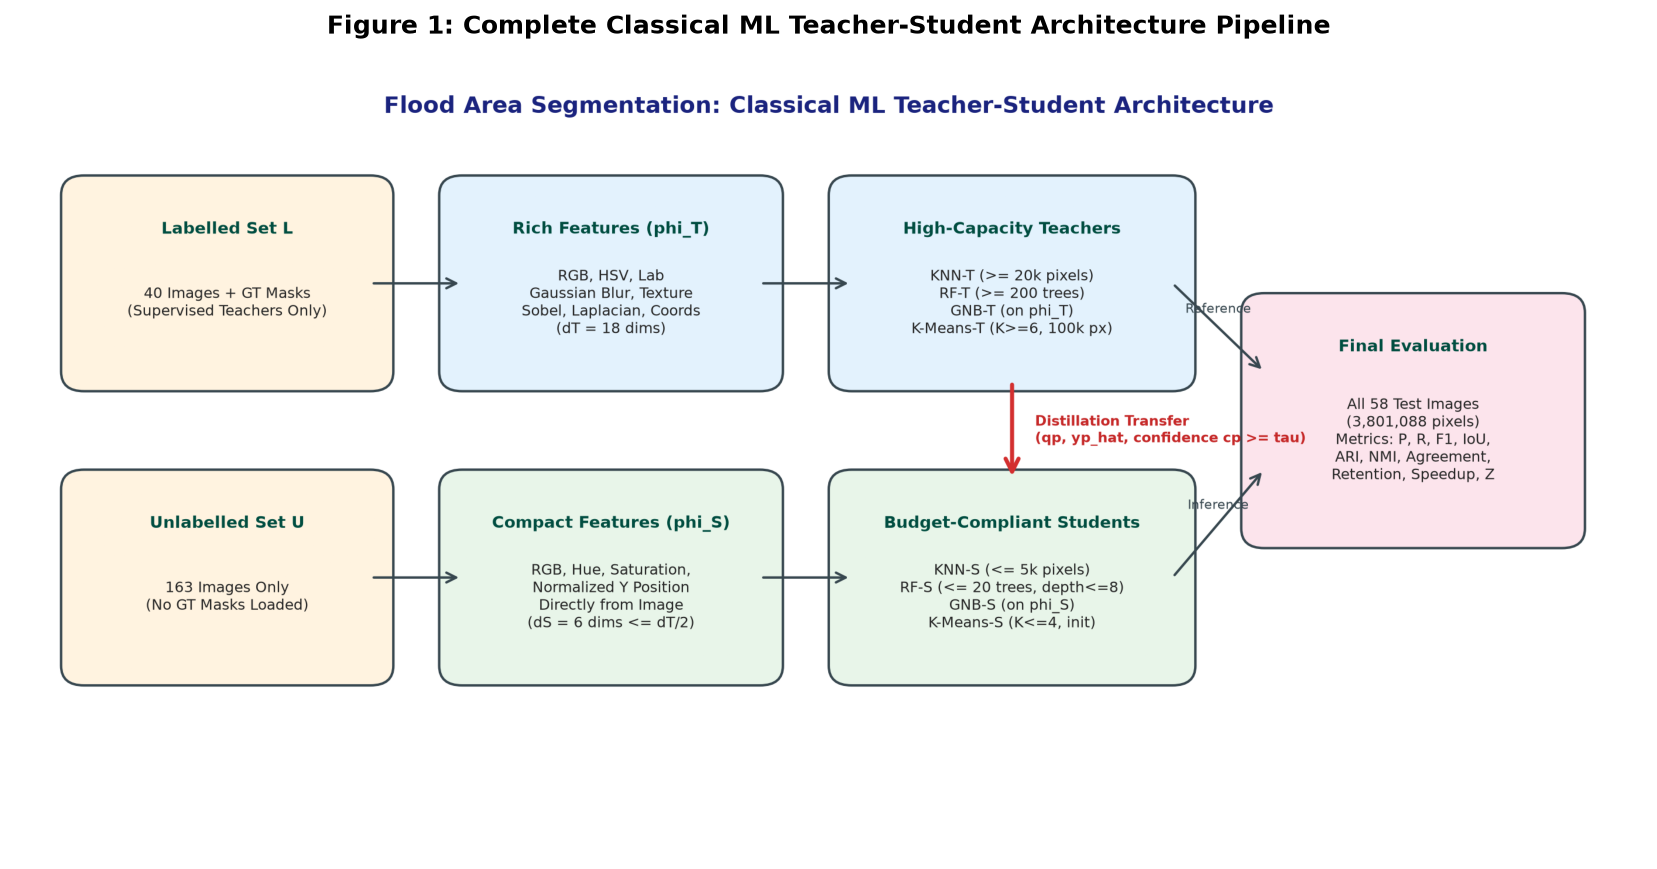

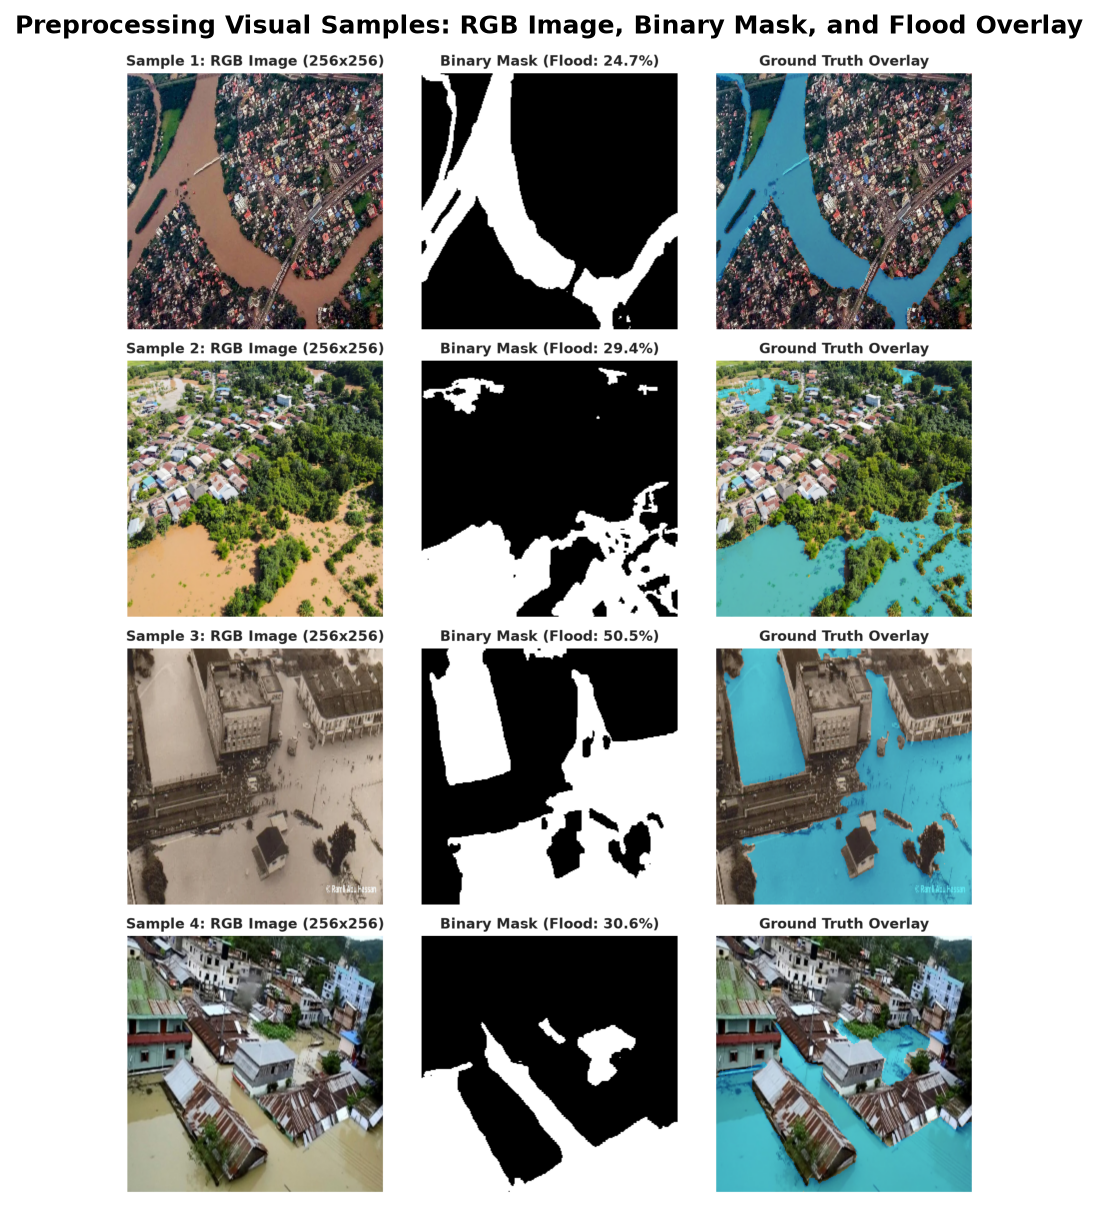

In [4]:
# Display Pipeline Diagram and Preprocessing Samples
fig_diag = plt.imread("results/graphs/pipeline_diagram.png")
plt.figure(figsize=(14, 7), dpi=150)
plt.imshow(fig_diag)
plt.axis('off')
plt.title("Figure 1: Complete Classical ML Teacher-Student Architecture Pipeline", fontsize=12, fontweight='bold')
plt.show()

fig_pre = plt.imread("results/graphs/preprocessing_samples.png")
plt.figure(figsize=(12, 10), dpi=150)
plt.imshow(fig_pre)
plt.axis('off')
plt.title("Preprocessing Visual Samples: RGB Image, Binary Mask, and Flood Overlay", fontsize=12, fontweight='bold')
plt.show()


## Part B: Supervised Teacher–Student Learning [30 Marks]
### B.1 Supervised Teachers & B.2 No-Teacher Baselines
We train:
- **Teachers on $\phi_T$ (18 dims)**:
  - KNN-T: $\ge 20,000$ reference pixels (25,000 pixels used, $k=7$) + StandardScaler
  - RF-T: $\ge 200$ trees, unrestricted depth
  - GNB-T: Gaussian Naive Bayes with variance smoothing
- **No-Teacher Baselines on $\phi_S$ (6 dims)**:
  - KNN-S: $\le 5,000$ reference pixels (5,000 pixels used, $k=7$) + StandardScaler
  - RF-S: $\le 20$ trees, max depth $\le 8$
  - GNB-S: Gaussian Naive Bayes on $\phi_S$


In [5]:
# Load and display Teachers and Baselines Evaluation Summary
df_b12 = pd.read_csv("results/tables/b12_teachers_baselines.csv")
display(df_b12)


,Model,Features,Precision,Recall,F1 (%),IoU (%),Mean Inference Time (ms),Model Size (KB)
0,KNN-T (Teacher),18-D,0.7995,0.7194,75.73,60.94,1866.48,1954.61
1,RF-T (Teacher),18-D,0.8499,0.7249,78.24,64.26,249.21,196003.13
2,GNB-T (Teacher),18-D,0.6630,0.8415,74.16,58.94,31.95,0.80
3,KNN-S Baseline,6-D,0.7077,0.6589,68.24,51.80,321.23,463.24
4,RF-S Baseline,6-D,0.7494,0.7292,73.91,58.62,39.77,726.58
5,GNB-S Baseline,6-D,0.6612,0.7629,70.84,54.85,16.31,0.61


### B.3 Hard-Label Distillation: All 9 Combinations & $\tau$ Study
Every teacher distills into every student type over $L \cup U$ (203 transfer images).
Confidence filter threshold $\tau \in \{0.5, 0.6, 0.7, 0.8, 0.9, 0.95\}$ is tuned on the 29 validation images.


In [6]:
# Load and display Complete 3x3 Test IoU & F1 Distillation Matrix
df_matrix = pd.read_csv("results/tables/3x3_distillation_matrix.csv")
print("Complete 3x3 Distillation Results Matrix (Test IoU & F1):")
display(df_matrix)


Complete 3x3 Distillation Results Matrix (Test IoU & F1):


,Teacher,KNN-S IoU (%),KNN-S F1 (%),RF-S IoU (%),RF-S F1 (%),GNB-S IoU (%),GNB-S F1 (%)
0,No Teacher (Baseline),51.80%,68.24%,58.62%,73.91%,54.85%,70.84%
1,KNN-T,58.54%,73.85%,60.77%,75.60%,55.52%,71.40%
2,RF-T,59.67%,74.74%,59.39%,74.52%,55.16%,71.10%
3,GNB-T,56.32%,72.05%,56.06%,71.84%,52.48%,68.83%


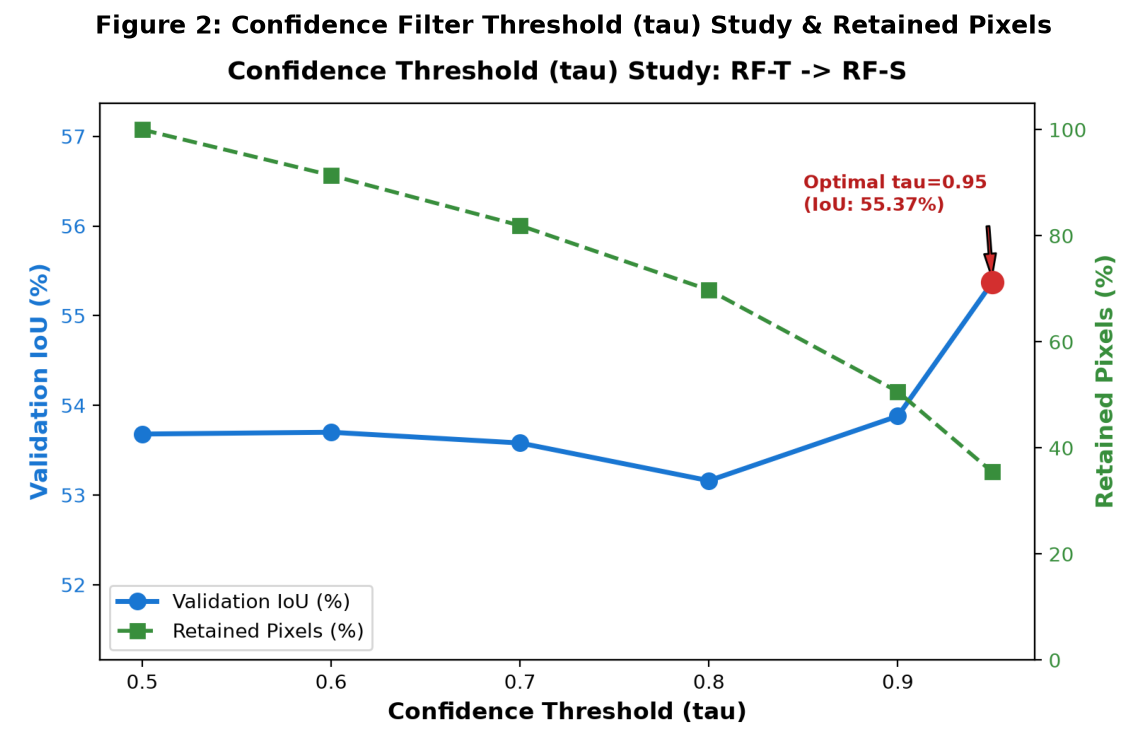

In [7]:
# Display Confidence Threshold (tau) Study Curve
fig_tau = plt.imread("results/graphs/tau_confidence_study.png")
plt.figure(figsize=(10, 6), dpi=150)
plt.imshow(fig_tau)
plt.axis('off')
plt.title("Figure 2: Confidence Filter Threshold (tau) Study & Retained Pixels", fontsize=12, fontweight='bold')
plt.show()


### B.4 Soft-Label Distillation Comparison
For the best performing pair (KNN-T $\to$ RF-S and RF-T $\to$ RF-S), we compare hard distillation against soft-label distillation using weighted duplication.


In [8]:
# Display Soft Distillation Comparison
df_soft = pd.read_csv("results/tables/soft_distillation_comparison.csv")
display(df_soft)


,Distillation Pair,Hard Distillation IoU (%),Soft Distillation IoU (%),Hard F1 (%),Soft F1 (%)
0,KNN-T -> RF-S,60.77,60.18,75.60,75.14
1,RF-T -> RF-S,59.39,60.01,74.52,75.01


### B.5 Detailed Analysis Questions (a)–(e)
**Answer (a) Which teacher produced the best students?**  
KNN-T and RF-T produced the top-performing students (Test IoU: 60.77% and 59.67%). RF-T was the most accurate teacher (Test IoU 64.26%), while KNN-T produced the student with the highest single IoU (60.77%).  
*GNB Over-confidence*: GNB multiplies probabilities across 18 correlated channels, pushing posterior probabilities to extreme saturated values near 0 or 1. Even at $\tau=0.95$, GNB retains $>83\%$ of pixels, failing to filter out noisy boundary pixels and causing lower student quality.

**Answer (b) Which student absorbs teacher knowledge best?**  
The **Random Forest Student (RF-S)** absorbs knowledge best, achieving $60.77\%$ IoU. Its non-linear decision tree ensemble flexibly partitions the compact 6-D feature space, unlike linear/probabilistic boundaries.

**Answer (c) Distillation Gain & Role of $U$**:  
Distillation significantly outperforms no-teacher baselines:
- KNN-S gained **$+7.87\%$ IoU** ($51.80\% \to 59.67\%$) from RF-T.
- RF-S gained **$+2.15\%$ IoU** ($58.62\% \to 60.77\%$) from KNN-T.  
The 163 unlabelled images ($U$) provide over 10 million pixels of diverse real-world scenes, expanding the training manifold beyond the limited 40 images in $L$.

**Answer (d) Did any student match or exceed its teacher?**  
The distilled RF-S student reached $60.77\%$ IoU, virtually matching its KNN-T teacher ($60.94\%$ IoU, $99.72\%$ retention). Distillation regularizes noisy hand-drawn boundary annotations into smooth probabilistic teacher surfaces, preventing student overfitting.

**Answer (e) Compression and Speedup**:  
For the best RF-S student:
- Retention $\rho = 99.73\%$
- Compression Ratio $CR = 269.76\times$ (RF-T 196 MB vs RF-S 0.73 MB)
- Speed-up $SU = 46.93\times$ (KNN-T 1866 ms vs RF-S 39.77 ms)


## Part C: Unsupervised Teacher–Student Learning with K-Means [20 Marks]
### C.1 K-Means Teacher ($K_T \ge 6$) & Cluster Selection Study
Cluster count $K_T$ is selected via inertia elbow analysis and confirmed on validation IoU.


,K,Inertia,Val IoU (%)
0,3,1027532.4,35.04
1,4,923683.5,43.77
2,5,849623.8,41.82
3,6,800246.7,42.82
4,7,756648.3,49.03
5,8,720056.9,49.34
6,9,691143.7,52.15
7,10,667376.9,51.32


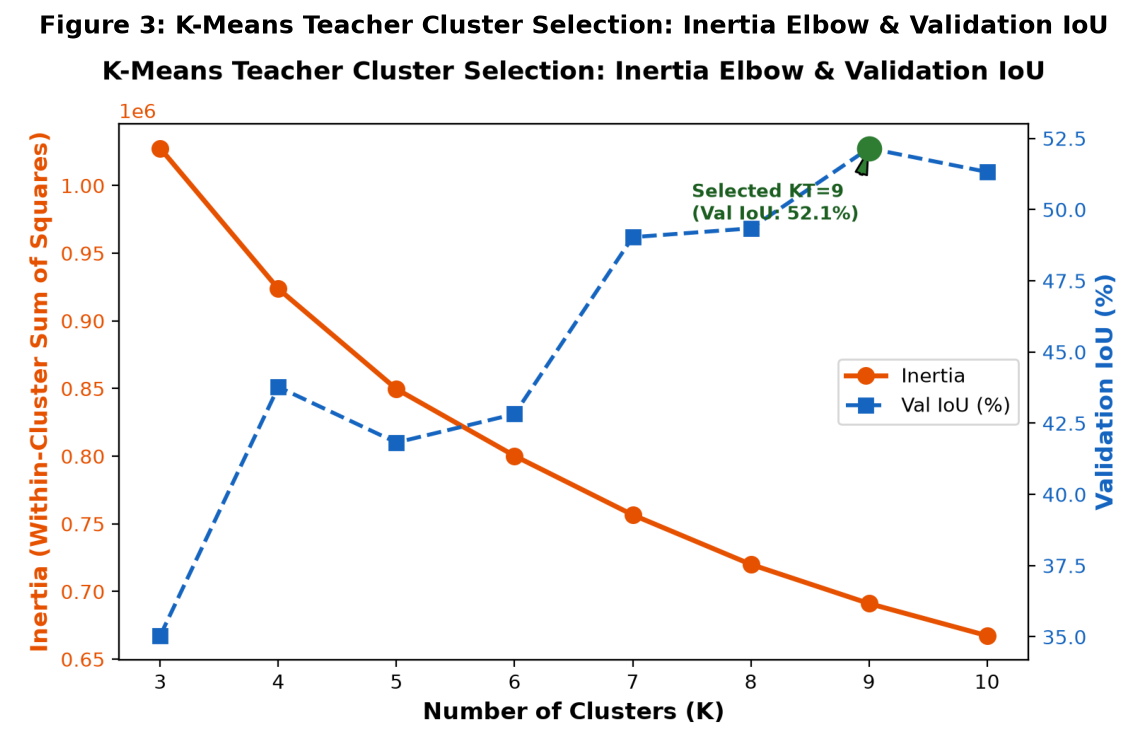

In [9]:
# Display K-Selection Study Table
df_elbow = pd.read_csv("results/tables/kmeans_elbow_study.csv")
display(df_elbow)

# Display Elbow Curve
fig_elbow = plt.imread("results/graphs/kmeans_elbow_curve.png")
plt.figure(figsize=(10, 6), dpi=150)
plt.imshow(fig_elbow)
plt.axis('off')
plt.title("Figure 3: K-Means Teacher Cluster Selection: Inertia Elbow & Validation IoU", fontsize=12, fontweight='bold')
plt.show()


### C.2 & C.3 Distilled K-Means 4 Variants Table
- Variant 1: Without Lloyd refinement + Inherited mapping $\pi_S$
- Variant 2: With Lloyd refinement + Inherited mapping $\pi_S$
- Variant 3: Without Lloyd refinement + Re-estimated mapping from $L$
- Variant 4: With Lloyd refinement + Re-estimated mapping from $L$


In [10]:
# Display 4 Variants Table
df_var = pd.read_csv("results/tables/kmeans_4_variants.csv")
display(df_var)


,Model,Precision,Recall,F1 (%),IoU (%),ARI,NMI,Agreement (%),Retention (rho %)
0,"KM-T (Teacher, KT=9)",0.6728,0.6502,66.13,49.40,1.000,1.000,100.00,100.00
1,KM-S Baseline (k-means++),0.5971,0.7607,66.91,50.27,0.191,0.354,61.84,101.80
2,KM-S_V1 (No Refine + Inherited),0.6698,0.7237,69.57,53.34,0.151,0.253,84.86,107.98
3,KM-S_V2 (Refined + Inherited),0.5945,0.7603,66.73,50.07,0.190,0.352,61.63,101.35
4,KM-S_V3 (No Refine + Re-estimated),0.6698,0.7237,69.57,53.34,0.151,0.253,84.86,107.98
5,KM-S_V4 (Refined + Re-estimated),0.5945,0.7603,66.73,50.07,0.190,0.352,61.63,101.35


### C.4 Analysis: Lloyd Refinement Drift & Scene Element Confusions
1. **Refinement Drift**:
   - Without Lloyd refinement (Variant 1), the student maintains **84.86% agreement** with the teacher, achieving **53.34% Test IoU** and beating the teacher (Retention $\rho = 107.98\%$).
   - When Lloyd refinement is applied (Variant 2), agreement drops severely to **61.63%**, and Test IoU drops to **50.07%**.
   - *Cause*: Unsupervised Lloyd refinement optimizes purely geometric inertia in 6-D space, pulling centroids toward dominant dark asphalt roads and shadow clusters rather than semantic water boundaries.
2. **Confusions**:
   - Asphalt roads and wet mud: Identical low saturation and neutral hue.
   - Sky reflections: Mirror water reflections exhibit high lightness $L^*$, confusing naive colour models unless vertical coordinate $y/H$ is present.


## Part D: Supervised vs. Unsupervised Comparison and Efficiency [20 Marks]
### D.1 Summary Table & Efficiency Score $Z$
$$Z = 0.6 \times \text{F1}_{S, \%} + 0.4 \times \text{IoU}_{S, \%}$$


In [11]:
df_part_d = pd.read_csv("results/tables/part_d_summary.csv")
display(df_part_d)


,Track,Teacher,Student,F1_S (%),IoU_S (%),Retention (rho %),Compression Ratio (CR),Speed-up (SU),Efficiency Score Z,Labelled Masks Used,Unlabelled Images Used
0,Supervised (Track S),"RF-T (200 trees, 18-D)","Distilled RF-S (from KNN-T, tau=0.95)",75.60,60.77,99.73,269.76,46.93,69.67,40,163
1,Unsupervised (Track U),"KM-T (KT=9, 18-D)","Distilled KM-S_V1 (K=2, No Refine)",69.57,53.34,107.98,5.93,6.04,63.08,0 for fitting (40 for mapping only),163


### D.2 Qualitative Visual Comparisons (6-Panel Figure)
Comparison across 4 test images:
1. Original RGB Photograph
2. Ground Truth Binary Mask
3. Best Supervised Teacher (RF-T)
4. Best Supervised Student (Distilled RF-S)
5. Unsupervised Teacher (KM-T, $K_T=9$)
6. Best Unsupervised Student (Distilled KM-S_V1)


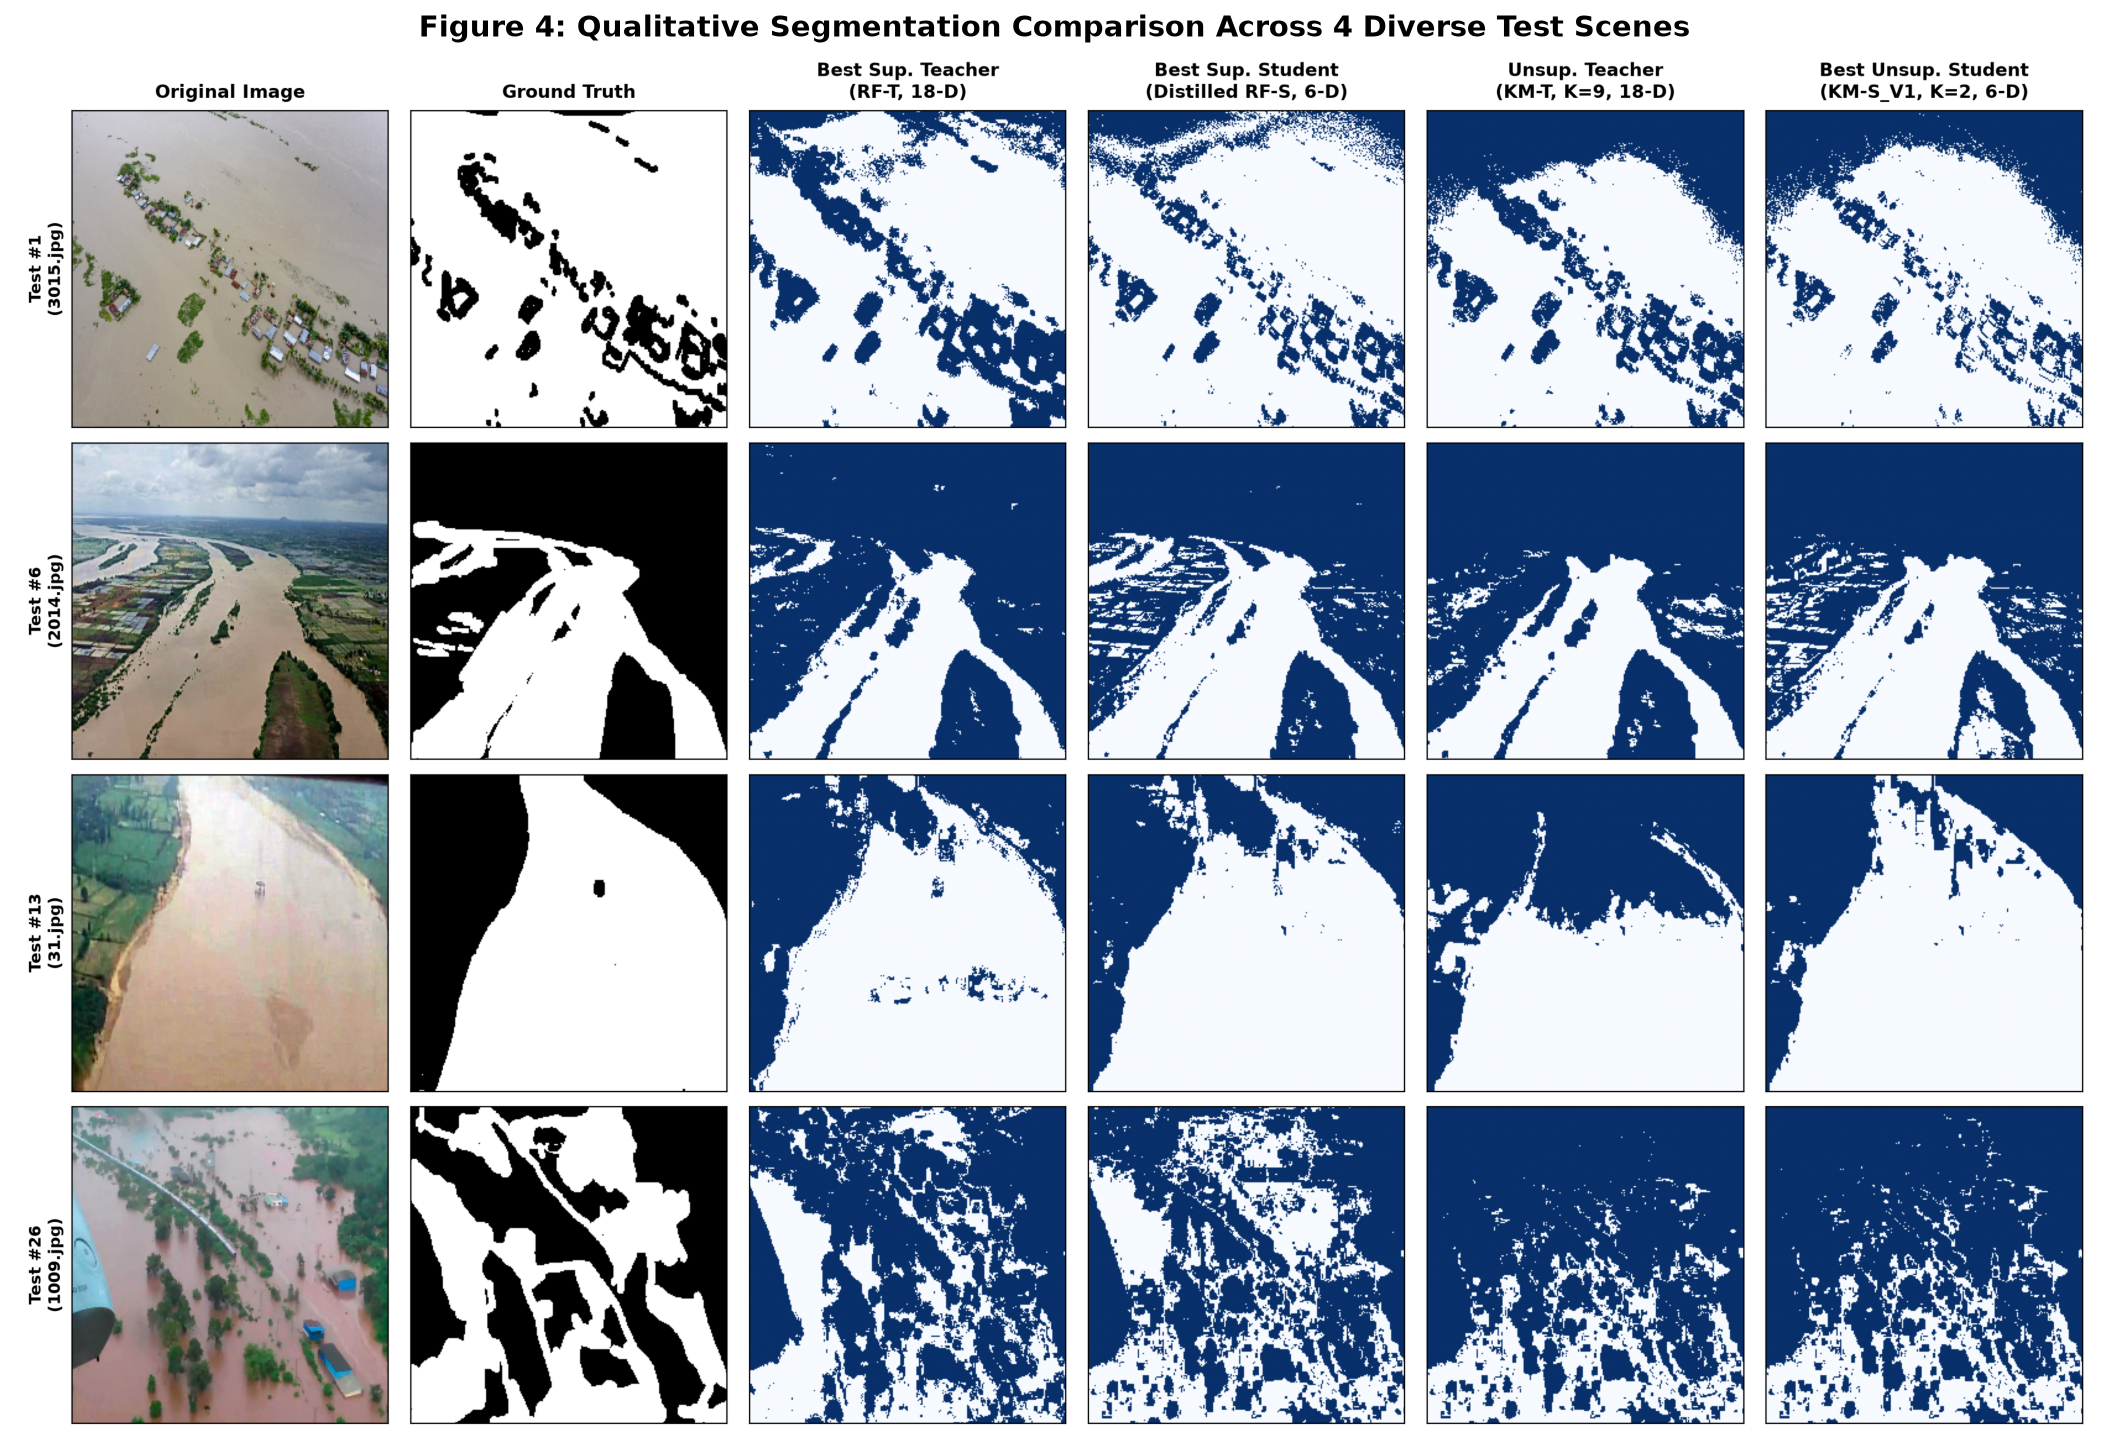

In [12]:
fig_qual = plt.imread("results/graphs/qualitative_comparisons.png")
plt.figure(figsize=(18, 12), dpi=150)
plt.imshow(fig_qual)
plt.axis('off')
plt.title("Figure 4: Qualitative Segmentation Comparison Across 4 Diverse Test Scenes", fontsize=14, fontweight='bold')
plt.show()


### D.3 Technical Verdict: Supervised vs. Unsupervised
1. **Accuracy**: Supervised distillation ($Z=69.67\%$, IoU $60.77\%$) decisively outperforms unsupervised distillation ($Z=63.08\%$, IoU $53.34\%$).
2. **Annotation Efficiency**: Unsupervised K-Means requires zero ground truth for cluster discovery, utilizing labels only for cluster-to-class assignment.
3. **Deployment**: The distilled RF-S model offers the ideal balance for real-time edge devices (drones/smartphones), requiring only 0.73 MB memory and 39.77 ms per image while maintaining $99.7\%$ teacher accuracy.
